## Initialization

In [2]:
import xarray as xr
# import matplotlib as plt
from matplotlib import pyplot as plt
import pandas as pd
import geopandas as gpd
from sklearn import linear_model
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import mean_squared_error, mean_absolute_error
from math import sqrt
import seaborn as sns
import numpy as np

#Choose whether to save plots
save_plots = False

# Change the matplotlib dpi to increase or decrease output size in vscode
plt.rcParams['figure.dpi'] = 150 

# Change some of the default xarray settings
xr.set_options(keep_attrs=True, display_expand_data=False)


def rmse(x,y):
    out = sqrt(mean_squared_error(x,y))
    return out




## Data Load-In

In [3]:

datapath = "/home/nlring/Documents/01_Research/larc-chicago-haq/datasets/"


fulldat = pd.read_csv(datapath+"fulldat-unaggregated-pixelmask.csv")
hourly = pd.read_csv(datapath+"fulldat-hourly-aggregation.csv")
hourly['datetime'] = pd.to_datetime(hourly['datetime'], errors='coerce')
hourly['hour'] = hourly['datetime'].dt.hour

diurnal = pd.read_csv(datapath+"fulldat-diurnal-aggregation.csv")
weekly = pd.read_csv(datapath+"fulldat-weekly-aggregation.csv")
monthly_diurnal = pd.read_csv(datapath+"fulldat-monthly-diurnal-aggregation.csv")
seasonal_diurnal = pd.read_csv(datapath+"fulldat-seasonal-diurnal-aggregation.csv")
monthly = pd.read_csv(datapath+"fulldat-monthly-aggregation.csv")



In [5]:
diurnal

,Unnamed: 0,hour,latitude,longitude,col_no2_mean,col_no2_median,col_no2_var,col_no2_sd,sfc_no2_mean,sfc_no2_median,...,pbl_mean,pbl_median,windspeed_2m_mean,windspeed_2m_median,winddir_2m_mean,winddir_2m_median,windspeed_10m_mean,windspeed_10m_median,winddir_10m_mean,winddir_10m_median
0,0,0,41.27,-88.25,NaN,NaN,NaN,NaN,NaN,NaN,...,963.176471,825.5,3.056849,2.598790,169.081467,157.138800,3.056849,2.598790,169.081467,157.138800
1,1,0,41.27,-88.23,NaN,NaN,NaN,NaN,NaN,NaN,...,963.352941,825.5,3.056849,2.598790,169.081467,157.138800,3.056849,2.598790,169.081467,157.138800
2,2,0,41.27,-88.21,NaN,NaN,NaN,NaN,NaN,NaN,...,963.529412,825.5,3.056849,2.598790,169.081467,157.138800,3.056849,2.598790,169.081467,157.138800
3,3,0,41.27,-88.19,NaN,NaN,NaN,NaN,NaN,NaN,...,963.558824,825.5,3.056849,2.598790,169.081467,157.138800,3.056849,2.598790,169.081467,157.138800
4,4,0,41.27,-88.17,NaN,NaN,NaN,NaN,NaN,NaN,...,963.794118,825.5,3.056849,2.598790,169.081467,157.138800,3.056849,2.598790,169.081467,157.138800
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49603,49603,23,42.41,-87.31,1.792981e+15,1.357120e+15,3.342545e+30,1.828263e+15,NaN,NaN,...,735.390805,668.0,4.384515,3.890399,156.177592,131.814905,4.384515,3.890399,156.177592,131.814905
49604,49604,23,42.41,-87.29,1.754518e+15,1.220937e+15,3.071995e+30,1.752711e+15,NaN,NaN,...,735.402299,667.5,4.384515,3.890399,156.177592,131.814905,4.384515,3.890399,156.177592,131.814905
49605,49605,23,42.41,-87.27,1.771422e+15,1.144443e+15,2.756903e+30,1.660393e+15,NaN,NaN,...,735.356322,668.0,4.384515,3.890399,156.177592,131.814905,4.384515,3.890399,156.177592,131.814905
49606,49606,23,42.41,-87.25,1.939276e+15,1.579176e+15,2.636611e+30,1.623764e+15,NaN,NaN,...,735.385057,668.5,4.384515,3.890399,156.177592,131.814905,4.384515,3.890399,156.177592,131.814905


## Multivariate Linear Regression - Full

Coef:  [ 3.59023097e-16 -7.34937127e-30]
Rank:  1
Intercept:  [11.50416595]
0.06362338278373747
               datetime  latitude  longitude  sfc_no2_mean  col_no2_mean  \
132 2025-09-04 12:00:00     41.65     -87.61       11.3000  4.143457e+15   
133 2025-09-04 12:00:00     41.65     -87.57       10.1775  4.125239e+15   
134 2025-09-04 12:00:00     41.65     -87.55       10.1250  4.081628e+15   
135 2025-09-04 12:00:00     41.65     -87.53       13.9525  4.084887e+15   
136 2025-09-04 12:00:00     41.67     -87.67       12.5975  5.040097e+15   

     pbl_mean  no2_estimate  
132     367.0     12.991763  
133     366.0     12.985222  
134     367.0     12.969565  
135     366.0     12.970735  
136     346.0     13.313677  


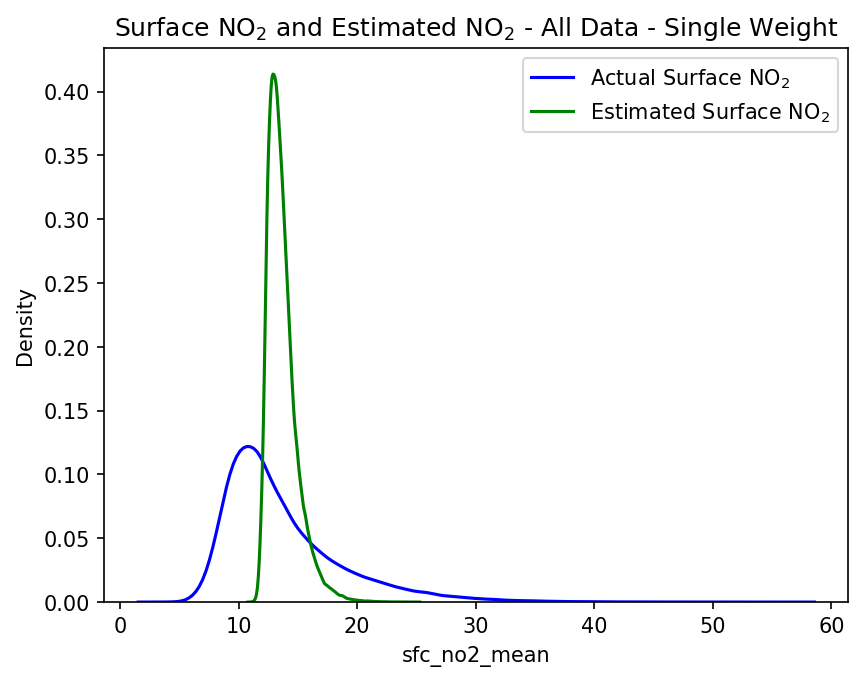

In [ ]:

vals = fulldat[['datetime','latitude','longitude','sfc_no2_mean','col_no2_mean','pbl_mean','windspeed_2m',]].dropna()


x = vals[['col_no2_mean','pbl_mean']]
y = vals[['sfc_no2_mean']]

model = linear_model.LinearRegression().fit(X=x, y=y)
score = model.score(X=x, y=y)

coef = np.ravel(model.coef_)
rank = np.ravel(model.rank_)[0]
intercept = np.ravel(model.intercept_)

print("Coef: ", coef)
print("Rank: ", rank)
print("Intercept: ", intercept)

print(score)

def estimate_no2(no2, pbl):
    out = float(intercept[0]) + float(coef[0])*no2 + float(coef[1])*pbl 
    return out

#.apply(lambda x: estimate_no2(vals.col_no2_mean, vals.pbl_mean), axis=1)

vals['no2_estimate'] = vals.apply(lambda x: estimate_no2(x.col_no2_mean, x.pbl_mean), axis=1)

# vals['no2_estimate'] = vals['col_no2_mean'].apply(lambda x: x*float(coef)+float(intercept))
print(vals.head())

sns.kdeplot(vals, x="sfc_no2_mean", color="blue", label='Actual Surface NO$_2$')
sns.kdeplot(vals, x='no2_estimate', color="green", label='Estimated Surface NO$_2$')
plt.title("Surface NO$_2$ and Estimated NO$_2$ - All Data - Single Weight")
plt.legend()
savefig("kde-actual-and-estimated-single-weight.png")
plt.show()

# eqn_text = f"y = {coef:.3e}x + {intercept:.2f}\n$R^2$ = {score:.3f}"
# print(eqn_text)

# plt.scatter(x, y, color='grey', alpha=0.1)
# plt.plot(x, model.predict(x),color='k' )
# plt.title("Column NO2 vs Surface NO2 Regression")
# plt.xlabel("Column NO2 (molecules/m$^2$)")
# plt.ylabel("Surface NO2 (ppb)")
# plt.annotate(eqn_text, xy=(0.05, 0.95), xycoords='axes fraction',
#              ha='left', va='top', fontsize=10,
#              bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

# savefig("column-no2-vs-sfc-no2-alldata.png")
# plt.show()



## Multivariate Linear Regression - Hourly

In [1]:

vals = diurnal[['hour','latitude','longitude',
                'sfc_no2_mean','col_no2_mean','pbl_mean',
                'windspeed_2m_mean','winddir_2m_mean',
                'windspeed_10m_mean','winddir_10m_mean']].dropna()

model_rows = []
for hour in sorted(vals['hour'].dropna().unique()):
    x_hour = vals.loc[vals['hour'] == hour, ['col_no2_mean', 'pbl_mean','windspeed_2m_mean']]

    y_hour = vals.loc[vals['hour'] == hour, ['sfc_no2_mean']]

    hour_model = linear_model.LinearRegression().fit(X=x_hour, y=y_hour)
    model_rows.append({
        'hour': hour,
        'no2_coef': float(hour_model.coef_.ravel()[0]),
        'pbl_coef': float(hour_model.coef_.ravel()[1]),
        'ws_coef': float(hour_model.coef_.ravel()[2]),
        'intercept': float(hour_model.intercept_.ravel()[0]),
        'score': hour_model.score(X=x_hour, y=y_hour)
    })







model_vals = pd.DataFrame(model_rows)
print(model_vals)

vals = vals.merge(model_vals, on="hour", how="outer")


NameError: name 'diurnal' is not defined

# MLR - Seasonal Hourly

      hour  latitude  longitude  sfc_no2_mean  col_no2_mean   pbl_mean  \
0       11     41.65     -87.61     17.338717  5.512069e+15  344.08844   
1       11     41.65     -87.57     16.036345  5.506295e+15  348.98640   
2       11     41.65     -87.55     11.447561  5.809331e+15  349.01360   
3       11     41.65     -87.53     14.873769  6.039262e+15  349.00000   
4       11     41.67     -87.67     16.086396  5.892401e+15  330.18370   
...    ...       ...        ...           ...           ...        ...   
2192    23     42.01     -87.79     13.897651  5.042380e+15  729.03930   
2193    23     42.01     -87.77     13.964287  5.033631e+15  729.12360   
2194    23     42.01     -87.71     13.686710  4.627226e+15  731.61017   
2195    23     42.01     -87.69     12.787973  4.743135e+15  731.71185   
2196    23     42.01     -87.67     14.075227  4.611781e+15  731.74580   

      no2_estimate    no2_coef_x    pbl_coef_x  intercept_x   score_x  \
0        12.198282  7.643691e-16 -3.48

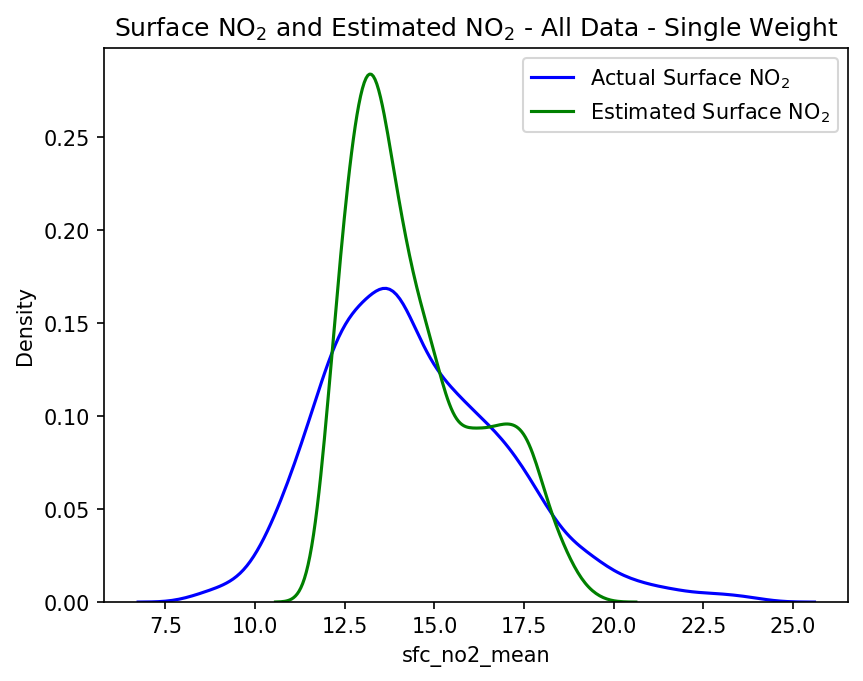

In [ ]:
def estimate_no2_fun(no2, pbl, coef1, coef2, intercept):
    out = float(intercept) + float(coef1)*no2 + float(coef2)*pbl 
    return out


print(vals)

# vals['no2_estimate'] = vals.apply(lambda x: estimate_no2(x.col_no2_mean, x.pbl_mean), axis=1)

vals['no2_estimate'] = vals['intercept'] + vals['no2_coef_x']*vals['col_no2_mean'] + vals['pbl_coef_x']*vals['pbl_mean'] 

sns.kdeplot(vals, x="sfc_no2_mean", color="blue", label='Actual Surface NO$_2$')
sns.kdeplot(vals, x='no2_estimate', color="green", label='Estimated Surface NO$_2$')
plt.title("Surface NO$_2$ and Estimated NO$_2$ - Hourly Weights")
plt.legend()
savefig("kde-actual-and-estimated-single-weight.png")
plt.show()
